# 07 · 规模估算、因果测试与研究边界

**Source audit:** [karpathy/nanoGPT](https://github.com/karpathy/nanoGPT/tree/3adf61e154c3fe3fca428ad6bc3818b27a3b8291) at `3adf61e154c3`; relevant files: `model.py`, `train.py`, `sample.py`, `data/shakespeare_char/prepare.py`, `config/train_shakespeare_char.py`.

**Scope:** The notebook uses a small **educational adaptation** (`nanogpt_edu.py`) consistent with the original architecture, not a verbatim copy of the full upstream training program. No pretrained weights, external datasets, downloads, distributed GPUs, or performance reproduction are claimed. Figures and prints are generated by real local CPU executions. The project's README has marked nanoGPT deprecated since Nov 2025 and points to nanochat.

## 用可复现实验证明结论，而不是猜测

nanoGPT 的默认 GPT-2 规模远超本地教学配置。这里绘制小模型尺寸的**真实 parameter count** 和**公式估算**的注意力矩阵元素数，并使用因果不变量测试检查未来 token 是否泄漏。

In [1]:
from pathlib import Path
import sys, torch, numpy as np, matplotlib.pyplot as plt
from IPython.display import display
# Compatible with starting Jupyter from the notebook directory OR repository root.
P = Path.cwd().resolve()
ROOT = P if (P / 'nanogpt_edu.py').exists() else P.parent
if not (ROOT / 'nanogpt_edu.py').exists():
    raise RuntimeError('Open this notebook from tutorials/nanogpt/notebooks or the tutorials/nanogpt directory')
sys.path.insert(0, str(ROOT))
from nanogpt_edu import GPTConfig, GPT, char_dataset, get_batch, training_text, lr_schedule, parameter_groups
OUT = ROOT / 'outputs'
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
torch.set_num_threads(min(2, torch.get_num_threads()))
torch.manual_seed(42); np.random.seed(42)
print('Python:', sys.version.split()[0], '| PyTorch:', torch.__version__, '| CPU tutorial', '| path:', ROOT)

Python: 3.13.5 | PyTorch: 2.10.0+cpu | CPU tutorial | path: /mnt/notebook-builder/tutorials/nanogpt


Parameter counts (rows=n_layer, cols=n_embd):
[[  4464  15072  54720]
 [  7744  27776 104704]
 [ 14304  53184 204672]]


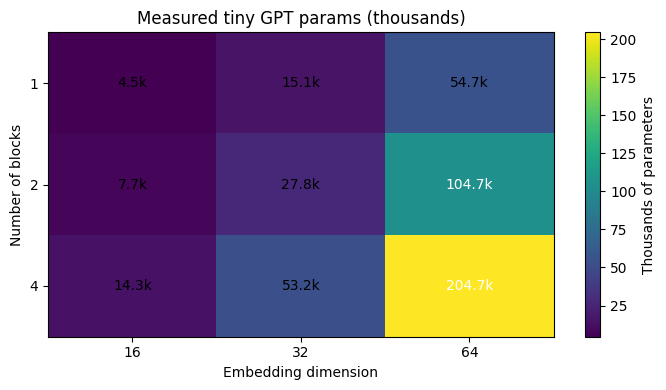

In [2]:
embs=[16,32,64];layers=[1,2,4]
counts=np.zeros((len(layers),len(embs)),dtype=int)
for i,L in enumerate(layers):
    for j,C in enumerate(embs):
        cfg=GPTConfig(vocab_size=40,block_size=32,n_layer=L,n_head=2,n_embd=C)
        counts[i,j]=sum(p.numel() for p in GPT(cfg).parameters())
print('Parameter counts (rows=n_layer, cols=n_embd):')
print(counts)
fig,ax=plt.subplots(figsize=(7,4));im=ax.imshow(counts/1000,aspect='auto')
ax.set_xticks(range(len(embs)),embs);ax.set_yticks(range(len(layers)),layers)
ax.set_xlabel('Embedding dimension');ax.set_ylabel('Number of blocks');ax.set_title('Measured tiny GPT params (thousands)')
for i in range(len(layers)):
    for j in range(len(embs)):ax.text(j,i,f'{counts[i,j]/1000:.1f}k',ha='center',va='center',color='white' if counts[i,j]>counts.max()/2 else 'black')
fig.colorbar(im,ax=ax,label='Thousands of parameters');fig.tight_layout()
fig.savefig(FIG/'07_parameter_scaling.png',dpi=140);display(fig);plt.close(fig)

Identical prefix (0..4) max logit difference: 0.0
Changed suffix (5..8) max logit difference: 0.6535525321960449


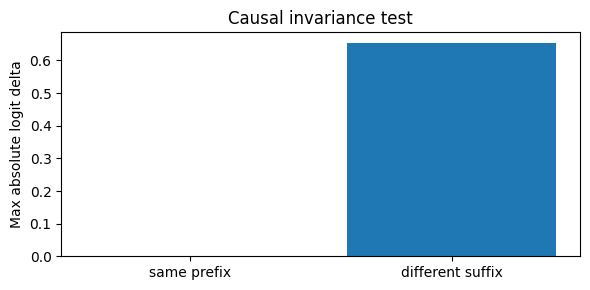

In [3]:
cfg=GPTConfig(vocab_size=32,block_size=16,n_layer=2,n_head=2,n_embd=32)
model=GPT(cfg).eval()
tokens_a=torch.tensor([[1,2,3,4,5,6,7,8,9]],dtype=torch.long)
tokens_b=tokens_a.clone();tokens_b[0,5:]=torch.tensor([9,8,7,6])
with torch.no_grad():
    logits_a,_=model(tokens_a,targets=tokens_a)
    logits_b,_=model(tokens_b,targets=tokens_b)
prefix_diff=(logits_a[:,:5,:]-logits_b[:,:5,:]).abs().max().item()
suffix_diff=(logits_a[:,5:,:]-logits_b[:,5:,:]).abs().max().item()
print('Identical prefix (0..4) max logit difference:',prefix_diff)
print('Changed suffix (5..8) max logit difference:',suffix_diff)
assert prefix_diff < 1e-6 and suffix_diff > 1e-7
fig,ax=plt.subplots(figsize=(6,3));ax.bar(['same prefix','different suffix'],[prefix_diff,suffix_diff]);ax.set_ylabel('Max absolute logit delta');ax.set_title('Causal invariance test');fig.tight_layout()
fig.savefig(FIG/'07_causal_invariance.png',dpi=130);display(fig);plt.close(fig)

Theoretical float32 B*H*T*T attention score MB: {np.int64(16): np.float64(0.016), np.int64(32): np.float64(0.062), np.int64(64): np.float64(0.25), np.int64(128): np.float64(1.0), np.int64(256): np.float64(4.0), np.int64(512): np.float64(16.0)}


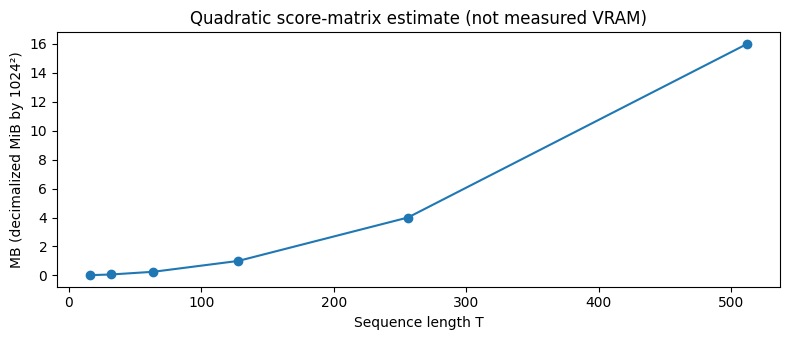

In [4]:
lengths=np.array([16,32,64,128,256,512]);B,H=4,4
# Only raw attention-score tensor estimate (float32), not real total memory use.
mb=B*H*lengths*lengths*4/1024**2
print('Theoretical float32 B*H*T*T attention score MB:',dict(zip(lengths,mb.round(3))))
fig,ax=plt.subplots(figsize=(8,3.5));ax.plot(lengths,mb,marker='o');ax.set_xlabel('Sequence length T');ax.set_ylabel('MB (decimalized MiB by 1024²)');ax.set_title('Quadratic score-matrix estimate (not measured VRAM)');fig.tight_layout()
fig.savefig(FIG/'07_attention_quadratic.png',dpi=130);display(fig);plt.close(fig)

### 审计清单

- **事实 vs 推断**：参数量由本地模型真实计数，`B×H×T²×4` 是密集 score matrix 的理论字节公式；优化后的 SDPA/Flash 实现并不一定存储此矩阵。
- **同样配置≠同样结果**：还需固定数据版本、随机数、PyTorch 版本与运行硬件。
- **本次未验证**：GPT-2 checkpoint 加载、OpenWebText 下载、DDP、多节点 GPU 和 nanoGPT 原仓库生产吞吐。

练习：给因果测试注入错误（去掉 causal mask），观察前缀测试怎样失败。